### Q11 Which brain area contains most information about variable A after outcome?

Variable A is binary. Information is quantified as the cross-validated ROC-AUC of a population decoder using only the `outcome` to `trial_end` portion of each retained trial. For every neuron and trial, the feature is its mean firing rate in `[outcome, trial_end)`; inter-trial activity and all earlier trial activity are excluded.

Decoding is performed separately within each mouse and brain area using an L2-regularized logistic regression. The same stratified five-fold trial splits are used for all three areas within a mouse. To prevent areas with more recorded units from receiving an advantage, every area is repeatedly subsampled to the smallest population recorded among the three areas in that mouse. Area summaries treat the mouse-level mean ROC-AUC as the observational unit.

This notebook deliberately matches the whole-trial Q11 analysis except for the firing-rate window, allowing a direct descriptive comparison of area performance during the post-outcome portion.

In [1]:
import csv
import os
import time
from collections import defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

#### Parameters

In [2]:
project_folder = Path("E:/con2phys_submission")
repository_folder = Path("D:/git_repos/con2phys_submission")
sua_csv_path = project_folder / "dataset" / "full_sua_dataset.csv"
trials_csv_path = repository_folder / "results" / "q11" / "trials_info_filtered.csv"
q_path = Path(os.environ.get(
    "Q11_OUTCOME_OUTPUT_DIR",
    repository_folder / "results" / "q11" / "outcome_trial_end",
))

N_NEURON_SUBSAMPLES = int(os.environ.get("Q11_N_SUBSAMPLES", 20))
N_CV_SPLITS = 5
RANDOM_SEED = 42
EXPECTED_N_MICE = 18
EXPECTED_N_UNITS = 1_449
EXPECTED_BRAIN_AREAS = (1, 2, 3)
MAX_MICE = (
    int(os.environ["Q11_MAX_MICE"])
    if os.environ.get("Q11_MAX_MICE")
    else None
)

run_tag = "full" if MAX_MICE is None else f"first_{MAX_MICE}_mice"
file_suffix = "" if MAX_MICE is None else f"_{run_tag}"
unit_counts_csv_path = q_path / f"outcome_trial_end_unit_counts{file_suffix}.csv"
subsamples_csv_path = q_path / f"outcome_trial_end_auc_subsamples{file_suffix}.csv"
mouse_area_csv_path = q_path / f"outcome_trial_end_auc_mouse_area{file_suffix}.csv"
area_summary_csv_path = q_path / f"outcome_trial_end_auc_area_summary{file_suffix}.csv"
figure_path = q_path / f"outcome_trial_end_auc_by_area{file_suffix}.png"

RUN_CONFIG = {
    "feature": "mean_firing_rate_outcome_to_trial_end",
    "interval_convention": "outcome_inclusive_trial_end_exclusive",
    "decoder": "standardized_l2_logistic_regression",
    "metric": "cross_validated_roc_auc",
    "cv": f"{N_CV_SPLITS}_fold_stratified_within_mouse",
    "neuron_matching": "minimum_area_population_within_mouse",
    "n_neuron_subsamples": N_NEURON_SUBSAMPLES,
    "random_seed": RANDOM_SEED,
    "max_mice": MAX_MICE,
}
RUN_CONFIG

{'feature': 'mean_firing_rate_outcome_to_trial_end',
 'interval_convention': 'outcome_inclusive_trial_end_exclusive',
 'decoder': 'standardized_l2_logistic_regression',
 'metric': 'cross_validated_roc_auc',
 'cv': '5_fold_stratified_within_mouse',
 'neuron_matching': 'minimum_area_population_within_mouse',
 'n_neuron_subsamples': 20,
 'random_seed': 42,
 'max_mice': None}

#### Load and validate filtered trials

The input table already excludes incomplete or incorrectly ordered trials and the final recorded trial for each mouse. The checks below ensure that the saved file still satisfies those conditions and that variable A is binary with enough observations from both classes for five-fold stratification.

In [3]:
required_paths = [sua_csv_path, trials_csv_path]
missing_paths = [path for path in required_paths if not path.exists()]
if missing_paths:
    raise FileNotFoundError(f"Required paths not found: {missing_paths}")

trials_df = pd.read_csv(trials_csv_path)
expected_trial_columns = [
    "mouse_id", "trial_id", "variable_A", "variable_B", "variable_C",
    "trial_start", "stim_start", "outcome", "trial_end", "trial_duration",
]
if list(trials_df.columns) != expected_trial_columns:
    raise ValueError(f"Unexpected trial schema: {list(trials_df.columns)}")
if trials_df[expected_trial_columns].isna().any().any():
    raise ValueError("Filtered trial table contains missing values")
if trials_df[["mouse_id", "trial_id"]].duplicated().any():
    raise ValueError("Duplicate mouse/trial identifiers found")

correct_order = (
    trials_df["trial_start"].lt(trials_df["stim_start"])
    & trials_df["stim_start"].lt(trials_df["outcome"])
    & trials_df["outcome"].lt(trials_df["trial_end"])
)
if not correct_order.all():
    raise ValueError("Filtered trial table contains incorrectly ordered events")
calculated_duration = trials_df["trial_end"] - trials_df["trial_start"]
if not np.allclose(
    trials_df["trial_duration"], calculated_duration, rtol=0, atol=1e-9
):
    raise ValueError("trial_duration does not match trial_end - trial_start")

observed_a = set(trials_df["variable_A"].unique())
if observed_a != {0, 1}:
    raise ValueError(f"variable_A must be binary 0/1; found {observed_a}")

all_mouse_ids = sorted(trials_df["mouse_id"].unique())
if len(all_mouse_ids) != EXPECTED_N_MICE:
    raise ValueError(
        f"Expected {EXPECTED_N_MICE} mice, found {len(all_mouse_ids)}"
    )
selected_mouse_ids = (
    all_mouse_ids if MAX_MICE is None else all_mouse_ids[:MAX_MICE]
)
trials_df = (
    trials_df.loc[trials_df["mouse_id"].isin(selected_mouse_ids)]
    .sort_values(["mouse_id", "trial_id"])
    .reset_index(drop=True)
)
class_counts = pd.crosstab(trials_df["mouse_id"], trials_df["variable_A"])
if (class_counts.min(axis=1) < N_CV_SPLITS).any():
    raise ValueError("A mouse has too few trials from one class for the requested CV")

trials_by_mouse = {
    int(mouse_id): group.reset_index(drop=True)
    for mouse_id, group in trials_df.groupby("mouse_id", sort=True)
}
display(class_counts.rename(columns={0: "A=0", 1: "A=1"}))
print(
    f"Validated {len(trials_df):,} trials from "
    f"{len(selected_mouse_ids)} mice."
)

variable_A,A=0,A=1
mouse_id,,
1,73,334
2,88,761
3,97,376
4,26,478
5,94,329
6,98,372
7,117,358
8,146,516
9,107,472


Validated 10,350 trials from 18 mice.


#### Extract outcome-to-trial-end firing rates

The approximately 802 MB SUA file is streamed one unit at a time. Spike counts in `[outcome, trial_end)` are found with binary searches in each sorted spike train. Counts are divided by the corresponding outcome-to-end duration, producing one trial-by-neuron firing-rate matrix for each mouse and brain area.

In [4]:
expected_sua_columns = [
    "mouse_id", "cluster_id", "brain_area", "recording_duration_sec",
    "unit_last_spike_sec", "n_spikes", "spikes",
]
rate_columns_by_group = defaultdict(list)
cluster_ids_by_group = defaultdict(list)
unit_keys = set()
n_source_units = 0

csv.field_size_limit(2**31 - 1)
load_started = time.perf_counter()
with sua_csv_path.open(newline="", encoding="utf-8") as handle:
    reader = csv.DictReader(handle)
    if reader.fieldnames != expected_sua_columns:
        raise ValueError(f"Unexpected SUA schema: {reader.fieldnames}")

    for row in reader:
        n_source_units += 1
        mouse_id = int(row["mouse_id"])
        if mouse_id not in trials_by_mouse:
            continue

        cluster_id = int(row["cluster_id"])
        brain_area = int(row["brain_area"])
        unit_key = (mouse_id, cluster_id)
        group_key = (mouse_id, brain_area)
        if unit_key in unit_keys:
            raise ValueError(f"Duplicate unit key: {unit_key}")
        if brain_area not in EXPECTED_BRAIN_AREAS:
            raise ValueError(f"Unexpected brain area for {unit_key}: {brain_area}")

        spike_times = np.fromstring(row["spikes"], sep=";", dtype=np.float64)
        expected_n_spikes = int(row["n_spikes"])
        if spike_times.size != expected_n_spikes or spike_times.size == 0:
            raise ValueError(f"Spike-count mismatch for {unit_key}")
        if not np.isfinite(spike_times).all() or np.any(np.diff(spike_times) < 0):
            raise ValueError(f"Invalid or unsorted spikes for {unit_key}")

        mouse_trials = trials_by_mouse[mouse_id]
        trial_outcomes = mouse_trials["outcome"].to_numpy(dtype=float)
        trial_ends = mouse_trials["trial_end"].to_numpy(dtype=float)
        segment_durations = trial_ends - trial_outcomes
        if not np.isfinite(segment_durations).all() or np.any(segment_durations <= 0):
            raise ValueError(f"Invalid outcome-to-end durations for mouse {mouse_id}")

        left = np.searchsorted(spike_times, trial_outcomes, side="left")
        right = np.searchsorted(spike_times, trial_ends, side="left")
        firing_rates = (right - left) / segment_durations

        rate_columns_by_group[group_key].append(firing_rates)
        cluster_ids_by_group[group_key].append(cluster_id)
        unit_keys.add(unit_key)

if MAX_MICE is None and n_source_units != EXPECTED_N_UNITS:
    raise ValueError(
        f"Expected {EXPECTED_N_UNITS} SUA units, found {n_source_units}"
    )

expected_group_keys = {
    (int(mouse_id), int(area))
    for mouse_id in selected_mouse_ids
    for area in EXPECTED_BRAIN_AREAS
}
if set(rate_columns_by_group) != expected_group_keys:
    missing_groups = expected_group_keys - set(rate_columns_by_group)
    raise ValueError(f"Missing mouse/area groups: {sorted(missing_groups)}")

firing_rates_by_group = {}
unit_count_rows = []
for group_key in sorted(expected_group_keys):
    mouse_id, brain_area = group_key
    matrix = np.column_stack(rate_columns_by_group[group_key])
    expected_rows = len(trials_by_mouse[mouse_id])
    if matrix.shape[0] != expected_rows or not np.isfinite(matrix).all():
        raise ValueError(f"Invalid firing-rate matrix for {group_key}")
    firing_rates_by_group[group_key] = matrix
    unit_count_rows.append({
        "mouse_id": mouse_id,
        "brain_area": brain_area,
        "n_units": matrix.shape[1],
        "n_trials": matrix.shape[0],
    })

unit_counts_df = pd.DataFrame(unit_count_rows)
matched_units_by_mouse = (
    unit_counts_df.groupby("mouse_id")["n_units"].min().astype(int)
)
unit_counts_df["n_matched_units"] = unit_counts_df["mouse_id"].map(
    matched_units_by_mouse
)
q_path.mkdir(parents=True, exist_ok=True)
unit_counts_df.to_csv(unit_counts_csv_path, index=False)

print(
    f"Built {len(firing_rates_by_group)} outcome-to-end firing-rate matrices in "
    f"{time.perf_counter() - load_started:.1f} s."
)
display(unit_counts_df)

Built 54 outcome-to-end firing-rate matrices in 22.5 s.


,mouse_id,brain_area,n_units,n_trials,n_matched_units
0,1,1,59,407,7
1,1,2,22,407,7
2,1,3,7,407,7
3,2,1,40,849,19
4,2,2,20,849,19
5,2,3,19,849,19
6,3,1,47,473,12
7,3,2,26,473,12
8,3,3,12,473,12
9,4,1,34,504,6


#### Matched-population decoding

For each mouse, all areas use the same trials and cross-validation folds. Each area is subsampled to that mouse's smallest area population. Feature standardization is fitted within each training fold by the pipeline, preventing information leakage into the held-out trials.

In [5]:
def make_decoder():
    return make_pipeline(
        StandardScaler(),
        LogisticRegression(
            penalty="l2",
            solver="liblinear",
            class_weight="balanced",
            max_iter=1_000,
            random_state=RANDOM_SEED,
        ),
    )


rng = np.random.default_rng(RANDOM_SEED)
result_rows = []
decoding_started = time.perf_counter()

for mouse_number, mouse_id in enumerate(selected_mouse_ids, start=1):
    mouse_started = time.perf_counter()
    mouse_trials = trials_by_mouse[int(mouse_id)]
    y = mouse_trials["variable_A"].to_numpy(dtype=int)
    cv = StratifiedKFold(
        n_splits=N_CV_SPLITS,
        shuffle=True,
        random_state=RANDOM_SEED + int(mouse_id),
    )
    cv_splits = list(cv.split(np.zeros(y.size), y))
    n_matched_units = int(matched_units_by_mouse.loc[mouse_id])

    for subsample_id in range(1, N_NEURON_SUBSAMPLES + 1):
        for brain_area in EXPECTED_BRAIN_AREAS:
            group_key = (int(mouse_id), int(brain_area))
            full_matrix = firing_rates_by_group[group_key]
            selected_indices = np.sort(rng.choice(
                full_matrix.shape[1], size=n_matched_units, replace=False
            ))
            selected_cluster_ids = np.asarray(
                cluster_ids_by_group[group_key]
            )[selected_indices]
            x = full_matrix[:, selected_indices]

            probabilities = cross_val_predict(
                make_decoder(), x, y,
                cv=cv_splits,
                method="predict_proba",
                n_jobs=1,
            )[:, 1]
            auc = roc_auc_score(y, probabilities)
            result_rows.append({
                "mouse_id": int(mouse_id),
                "brain_area": int(brain_area),
                "subsample_id": subsample_id,
                "n_matched_units": n_matched_units,
                "n_trials": y.size,
                "n_A0": int((y == 0).sum()),
                "n_A1": int((y == 1).sum()),
                "roc_auc": auc,
                "cluster_ids": ";".join(map(str, selected_cluster_ids)),
            })

    elapsed = time.perf_counter() - mouse_started
    print(
        f"Mouse {mouse_id}: {n_matched_units} matched units, "
        f"{N_NEURON_SUBSAMPLES} subsamples, {elapsed:.1f} s "
        f"({mouse_number}/{len(selected_mouse_ids)})"
    )

auc_subsamples_df = pd.DataFrame(result_rows)
if not auc_subsamples_df["roc_auc"].between(0, 1).all():
    raise ValueError("ROC-AUC outside [0, 1]")
auc_subsamples_df.to_csv(subsamples_csv_path, index=False)
print(
    f"Completed {len(auc_subsamples_df):,} matched-area decoders in "
    f"{time.perf_counter() - decoding_started:.1f} s."
)
auc_subsamples_df.head()

C:\Users\ipochino\AppData\Local\anaconda3\envs\timescales\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\ipochino\AppData\Local\anaconda3\envs\timescales\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.

C:\Users\ipochino\AppData\Local\anaconda3\envs\timescales\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\ipochino\AppData\Local\anaconda3\envs\timescales\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.

C:\Users\ipochino\AppData\Local\anaconda3\envs\timescales\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\ipochino\AppData\Local\anaconda3\envs\timescales\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.

C:\Users\ipochino\AppData\Local\anaconda3\envs\timescales\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\ipochino\AppData\Local\anaconda3\envs\timescales\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.

C:\Users\ipochino\AppData\Local\anaconda3\envs\timescales\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\ipochino\AppData\Local\anaconda3\envs\timescales\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.

C:\Users\ipochino\AppData\Local\anaconda3\envs\timescales\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\ipochino\AppData\Local\anaconda3\envs\timescales\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.

... (127 outputs left out)

C:\Users\ipochino\AppData\Local\anaconda3\envs\timescales\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\ipochino\AppData\Local\anaconda3\envs\timescales\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.

Mouse 18: 12 matched units, 20 subsamples, 1.3 s (18/18)
Completed 1,080 matched-area decoders in 24.5 s.


C:\Users\ipochino\AppData\Local\anaconda3\envs\timescales\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\ipochino\AppData\Local\anaconda3\envs\timescales\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.

,mouse_id,brain_area,subsample_id,n_matched_units,n_trials,n_A0,n_A1,roc_auc,cluster_ids
0,1,1,1,7,407,73,334,0.838692,391;392;445;471;488;509;879
1,1,2,1,7,407,73,334,0.911738,709;732;758;762;787;790;937
2,1,3,1,7,407,73,334,0.845788,547;557;560;563;569;670;673
3,1,1,2,7,407,73,334,0.707735,391;404;419;435;468;479;489
4,1,2,2,7,407,73,334,0.903207,707;713;723;730;732;747;937


#### Mouse-level and brain-area summaries

Repeated neuron subsamples are averaged within each mouse and area. The area-level mean and descriptive 95% confidence interval are then calculated across the 18 mouse means, so mice with more units or more trials do not contribute additional weight. Formal paired inference between areas can be added separately.

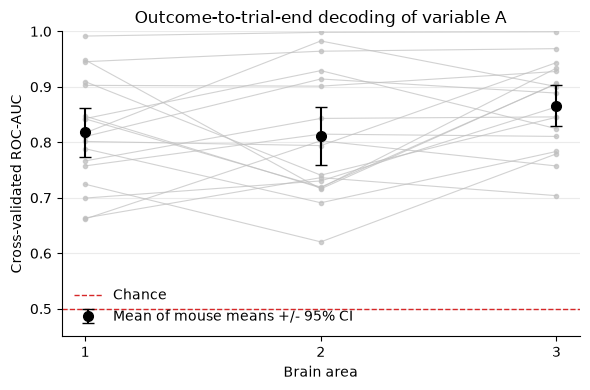

,mouse_id,brain_area,mean_roc_auc,sd_subsample_roc_auc,n_subsamples,n_matched_units,n_trials,n_A0,n_A1
0,1,1,0.766463,0.062836,20,7,407,73,334
1,1,2,0.843038,0.086616,20,7,407,73,334
2,1,3,0.845788,0.000000,20,7,407,73,334
3,2,1,0.816996,0.043083,20,19,849,88,761
4,2,2,0.982655,0.018432,20,19,849,88,761
5,2,3,0.900445,0.000000,20,19,849,88,761
6,3,1,0.810353,0.053218,20,12,473,97,376
7,3,2,0.914130,0.059004,20,12,473,97,376
8,3,3,0.888709,0.000000,20,12,473,97,376
9,4,1,0.724425,0.135226,20,6,504,26,478


,mean_roc_auc,sd_mouse_auc,n_mice,sem_roc_auc,ci95_margin,ci95_low,ci95_high
brain_area,,,,,,,
1,0.817771,0.096830,18,0.022823,0.044733,0.773038,0.862505
2,0.812012,0.112690,18,0.026561,0.052060,0.759952,0.864072
3,0.865974,0.078832,18,0.018581,0.036419,0.829556,0.902393


Highest descriptive mean ROC-AUC: brain area 3 (0.8660).


In [6]:
mouse_area_auc = (
    auc_subsamples_df.groupby(["mouse_id", "brain_area"], as_index=False)
    .agg(
        mean_roc_auc=("roc_auc", "mean"),
        sd_subsample_roc_auc=("roc_auc", "std"),
        n_subsamples=("roc_auc", "size"),
        n_matched_units=("n_matched_units", "first"),
        n_trials=("n_trials", "first"),
        n_A0=("n_A0", "first"),
        n_A1=("n_A1", "first"),
    )
)
area_summary = (
    mouse_area_auc.groupby("brain_area")["mean_roc_auc"]
    .agg(mean_roc_auc="mean", sd_mouse_auc="std", n_mice="count")
)
area_summary["sem_roc_auc"] = (
    area_summary["sd_mouse_auc"] / np.sqrt(area_summary["n_mice"])
)
area_summary["ci95_margin"] = 1.96 * area_summary["sem_roc_auc"]
area_summary["ci95_low"] = (
    area_summary["mean_roc_auc"] - area_summary["ci95_margin"]
)
area_summary["ci95_high"] = (
    area_summary["mean_roc_auc"] + area_summary["ci95_margin"]
)

mouse_area_auc.to_csv(mouse_area_csv_path, index=False)
area_summary.reset_index().to_csv(area_summary_csv_path, index=False)

fig, ax = plt.subplots(figsize=(6, 4))
for mouse_id, mouse_df in mouse_area_auc.groupby("mouse_id"):
    mouse_df = mouse_df.sort_values("brain_area")
    ax.plot(
        mouse_df["brain_area"], mouse_df["mean_roc_auc"],
        color="0.75", marker="o", markersize=3, linewidth=0.8, alpha=0.7,
    )

area_positions = area_summary.index.to_numpy(dtype=float)
ax.errorbar(
    area_positions,
    area_summary["mean_roc_auc"],
    yerr=area_summary["ci95_margin"],
    fmt="o", color="black", markersize=7, capsize=4, linewidth=1.5,
    label="Mean of mouse means +/- 95% CI",
)
ax.axhline(0.5, color="tab:red", linestyle="--", linewidth=1, label="Chance")
ax.set_xticks(EXPECTED_BRAIN_AREAS)
ax.set_xlabel("Brain area")
ax.set_ylabel("Cross-validated ROC-AUC")
ax.set_title("Outcome-to-trial-end decoding of variable A")
ax.set_ylim(0.45, 1.0)
ax.grid(True, axis="y", linestyle="-", alpha=0.25)
ax.legend(frameon=False, loc="best")
sns.despine(ax=ax)
fig.tight_layout()
fig.savefig(figure_path, dpi=200, bbox_inches="tight")
plt.show()

display(mouse_area_auc)
display(area_summary)
best_area = int(area_summary["mean_roc_auc"].idxmax())
print(
    f"Highest descriptive mean ROC-AUC: brain area {best_area} "
    f"({area_summary.loc[best_area, 'mean_roc_auc']:.4f})."
)